# Introduccion

**Trabajo Individual**

*Estudiante:* Pablo André Valenciano Blanco
*Empresa:* GameFreak

*Entorno:* Gamefreak desarrolladora de la franquicia mas exitosa del mundo conocida como Pokemon esta pasando por un bloqueo creativo, no tanto en lo que son diseños ya que la inspiración suele encontrarse en fanarts sino en la forma como se podrian interpretar dentro de los juegos, tanto en conocer los tipos que mas se apegan a cada diseño sin desalinearse de su propio estilo.

El Jefe, sabiendo mi conocimiento de uso de IA me solicita que diseñe 2 modelos y actividades que ayuden a que el trabajo sea más rapido de hacer y se eviten conflictos por discrepancia de pensamientos. A modo preparativo se pasa esta lista de tareas.


- Modelo supervisado de analisís de tipos:
  - [X] Modelo entrenado con todas las imegenes de pokemons existentes.
  - [X] Actividad 1: Dado un Pokemon se prediga el tipo de Pokemon.
  - [X] Actividad 2: Dado un tipo adivinar el pokemon por la imagen de este.
  - [X] Actividad 3: Dada una imagen/pokemon, ofrecer el porcentaje de cada tipo.
  - [ ] Actividad 4: A traves de la imagen ofrecer un nombre en lenguaje natural.
  - [ ] Actividad 5: Dado un nombre diseñar imagenes que parezcan pokemon.
  - [ ] Actividad 6: Hacer uso de herramientas LLM para dada una estadistica y corregir segun indicaciones de usuario.


- Modelo no supervisado de Estadisticas.
  - [X] Modelo que relacione las estadisticas con los tipos de Pokemon.
    1. Se debe dar los tipos de Pokemon
    2. Las estadisticas se deben predecir pero hay veces que el creador ya tiene idea de alguna de ellas.
    3. El modelo debe probar opciones desde que no se les de ninguna hasta que solo falte 1.
  - [X] Actividad 1. Prediccion deestadisticas solo con los tipos y estadisticas dadas por el usuario.
  - [ ] Actividad 2. Integracion de ambos modelos para que usando la imagen simule los 2 tipos en modo para predecir las estadisticas del Pokemon.
  - [ ] Actividad 3. Usar lenguaje natural para limpiar el por que de cada analisis.

  Dificultades:
  1. Tiempo: Al ser un trabajo de un mes, donde se debe: <br>
    a. Planificar (Definir Tareas) <br>
    b. Desarrollar (Desarrollo de las mismas) <br>
    c. Documentar (Presentacion de slides y revision de entregables) <br>
  2. Dataframe utilizado: Lastimosamente el unico df con la mayoria de Pokemones no tiene una de las columnas más importantes en diseño y es la etapa del Pokemon, la cual puede ser bebe, fase 1, fase 2, fase 3 y Mega. Pero al no poseerlo dificulta los analisis y sobretodo en lo que se refiere a las estadisticas cuando solo se dan los tipos.
  3. Limitación del proyecto: Para el proyecto no se haran las actividades no marcadas dado que no es requisito la generacion de elementos nuevos sino solo usar elementos que se conocen.

# Librerias a utilizar

In [ ]:
pip install tensorflow

In [34]:
import os
import time
import copy
import random
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms, models
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

# Para los minijuegos
import requests
import re
from io import BytesIO
from time import sleep
import torch.nn.functional as F

# Escanar de Aura
from google.colab import files
import io

# Para el analisis de poder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.losses import mse
import itertools
import joblib

# Configuración visual
sns.set_theme(style="whitegrid")
warnings.filterwarnings('ignore')

# Informacion Basica

In [7]:
EXCEL_FILE = 'pokedex.xlsx'
IMG_DIR = '.'
BATCH_SIZE = 32
NUM_EPOCHS = 4
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print(f"Usando dispositivo: {DEVICE}")

Usando dispositivo: cpu


### Informacion del dataframe

Archivo: pokedex.xlsx

Columnas:

**Images**: La ruta de la imagen de cada pokemon. Nexecisario para Actividad 1 y 2 de analisis de images.

**Index**: Posicion del Pokemon en la Pokedex.

**Name**: Nombre del Pokemon

**Type 1**: Tipo principal del Pokemon

**Type 2**: Tipo secundario puede no poseer

**Total**: Suma de las estadisticas

*Estadisticas*:

  - **HP**: Vida base del Pokemon
  - **Attack**: Ataque fisico base del Pokemon
  - **Defense**: Defensa fisica base del Pokemon
  - **Sp. Atk.**: Ataque Especial base del Pokemon
  - **Sp. Def.**: Defensa Especial base del Pokemon
  - **Speed**: Velocidad base del Pokemon

# EDA (Exploratory Data Anlasysis)

In [ ]:
"""
No generado LLM

Se crea de forma sintetica la columna type joint, la cual es la suma de string de ambos tipos.

La funcion preprocess_data diseña el df dado el excel.
Se requiere pokedex.xlsx en el directorio actual.
"""

def preprocess_data(file_path):
    """
    Carga los datos, elimina columnas innecesarias y crea 'Type Joint'.
    """
    print("--- 1. PREPROCESAMIENTO DE DATOS ---")

    # Cargar datos
    df = pd.read_excel(file_path)


    print(f"Datos cargados: {df.shape[0]} filas, {df.shape[1]} columnas.")

    # 1. Eliminar columnas Image e Index
    cols_to_drop = ['Image', 'Index']
    df = df.drop(columns=[c for c in cols_to_drop if c in df.columns], errors='ignore')

    # 2. Crear Type Joint (Orden Alfabético)
    def create_joint_type(row):
        t1 = str(row['Type 1'])
        t2 = str(row['Type 2']) if pd.notna(row['Type 2']) else None

        if t2:
            # Ordenar alfabéticamente para evitar duplicados como Grass_Poison vs Poison_Grass
            types = sorted([t1, t2])
            return f"{types[0]}_{types[1]}"
        else:
            return t1

    df['Type Joint'] = df.apply(create_joint_type, axis=1)

    print("Columnas eliminadas y 'Type Joint' creado exitosamente.")
    return df

# 1. Cargar y Preprocesar
df_pokemon = preprocess_data(EXCEL_FILE)

--- 1. PREPROCESAMIENTO DE DATOS ---
Datos cargados: 1215 filas, 12 columnas.
Columnas eliminadas y 'Type Joint' creado exitosamente.



--- 2. ANÁLISIS NUMÉRICO (HISTOGRAMAS Y ESTADÍSTICAS) ---
Tabla de Estadísticas Descriptivas:


,Media,Mediana,Desv. Std,Asimetría (Skew),Q1 (25%),Q3 (75%)
Total,443.104527,465.0,121.193406,0.120503,332.0,521.0
HP,71.244444,70.0,26.927819,1.606628,52.0,85.0
Attack,81.152263,80.0,32.037134,0.416642,57.0,100.0
Defense,75.007407,70.0,30.740999,1.104015,52.0,91.0
SP. Atk.,73.224691,65.0,32.757152,0.692224,50.0,95.0
SP. Def,72.441152,70.0,27.578188,0.871229,51.0,90.0
Speed,70.034568,68.0,30.161298,0.362885,45.0,91.0


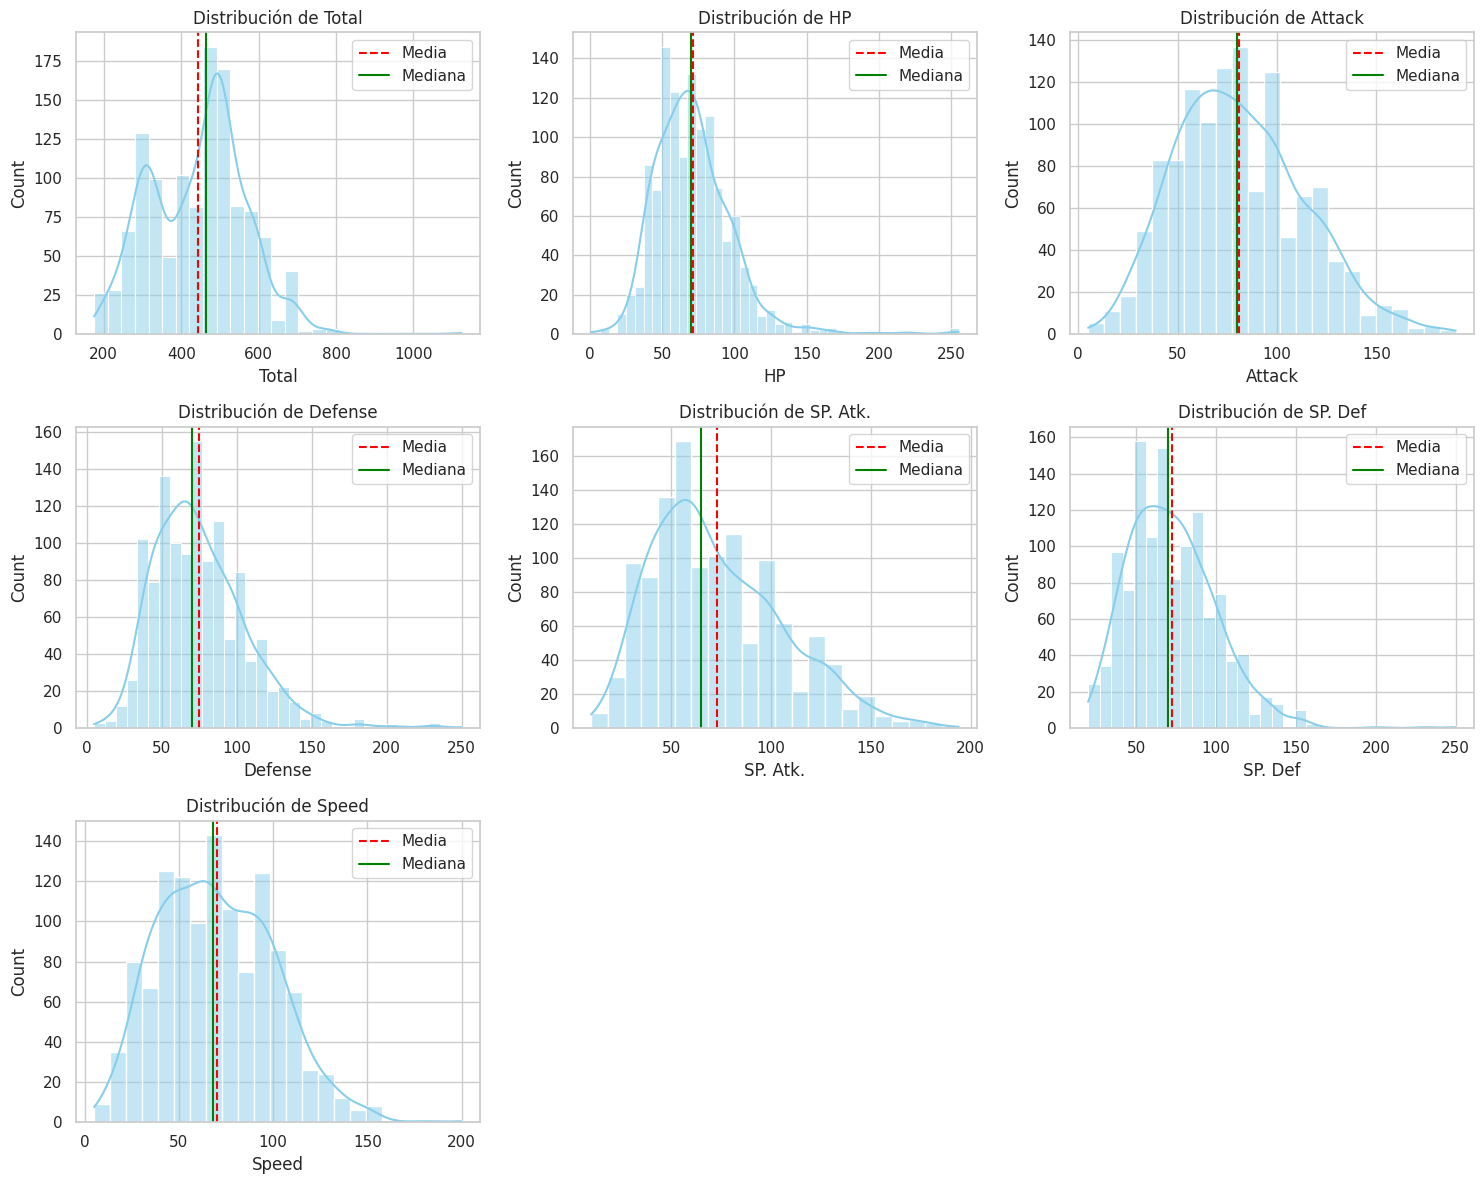

In [ ]:
"""
No generado LLM

Analisis estadistico de los datos numericos.

Se mostrara la tabla para facilitar la lectura de las estadisticas de la totalidad de los pokemones.
Y se graficara la distribucion en frecuencia de estas, en busca de normalizacion, si fuese necesaria en alguna de estas.
"""
def analyze_numerical_distribution(df):
    """
    Genera histogramas y una tabla estadística detallada (Media, Mediana, Q1, Q3, Asimetría).
    """
    print("\n--- 2. ANÁLISIS NUMÉRICO (HISTOGRAMAS Y ESTADÍSTICAS) ---")

    # Seleccionar solo columnas numéricas
    numeric_cols = df.select_dtypes(include=[np.number]).columns

    # Crear Tabla de Estadísticas
    stats_df = df[numeric_cols].agg(['mean', 'median', 'std', 'skew'])

    # Calcular percentiles manualmente y añadir
    percentiles = df[numeric_cols].quantile([0.25, 0.75])
    stats_df = pd.concat([stats_df, percentiles])

    # Renombrar índices para claridad
    stats_df.index = ['Media', 'Mediana', 'Desv. Std', 'Asimetría (Skew)', 'Q1 (25%)', 'Q3 (75%)']

    print("Tabla de Estadísticas Descriptivas:")
    display(stats_df.T) # Transpuesta para mejor lectura

    # Graficar Histogramas
    num_plots = len(numeric_cols)
    cols = 3
    rows = (num_plots // cols) + (1 if num_plots % cols > 0 else 0)

    plt.figure(figsize=(15, 4 * rows))
    for i, col in enumerate(numeric_cols):
        plt.subplot(rows, cols, i+1)
        sns.histplot(df[col], kde=True, color='skyblue')
        plt.title(f'Distribución de {col}')
        plt.axvline(df[col].mean(), color='red', linestyle='--', label='Media')
        plt.axvline(df[col].median(), color='green', linestyle='-', label='Mediana')
        plt.legend()

    plt.tight_layout()
    plt.show()

# 2. Análisis Numérico (Histogramas + Tabla Stats)
analyze_numerical_distribution(df_pokemon)

### Observacion 1

Excepto Total, todos los valores de las estadisticas poseen distribucion muy similar a la normal, por lo que se decide no normalizar los datos y ahora en el procesamiento de los datos predictorios.

En las 7 figuras se ve que la mediana y la moda tienden asemejarse mucho.


--- 3. ANÁLISIS CATEGÓRICO (FRECUENCIAS) ---


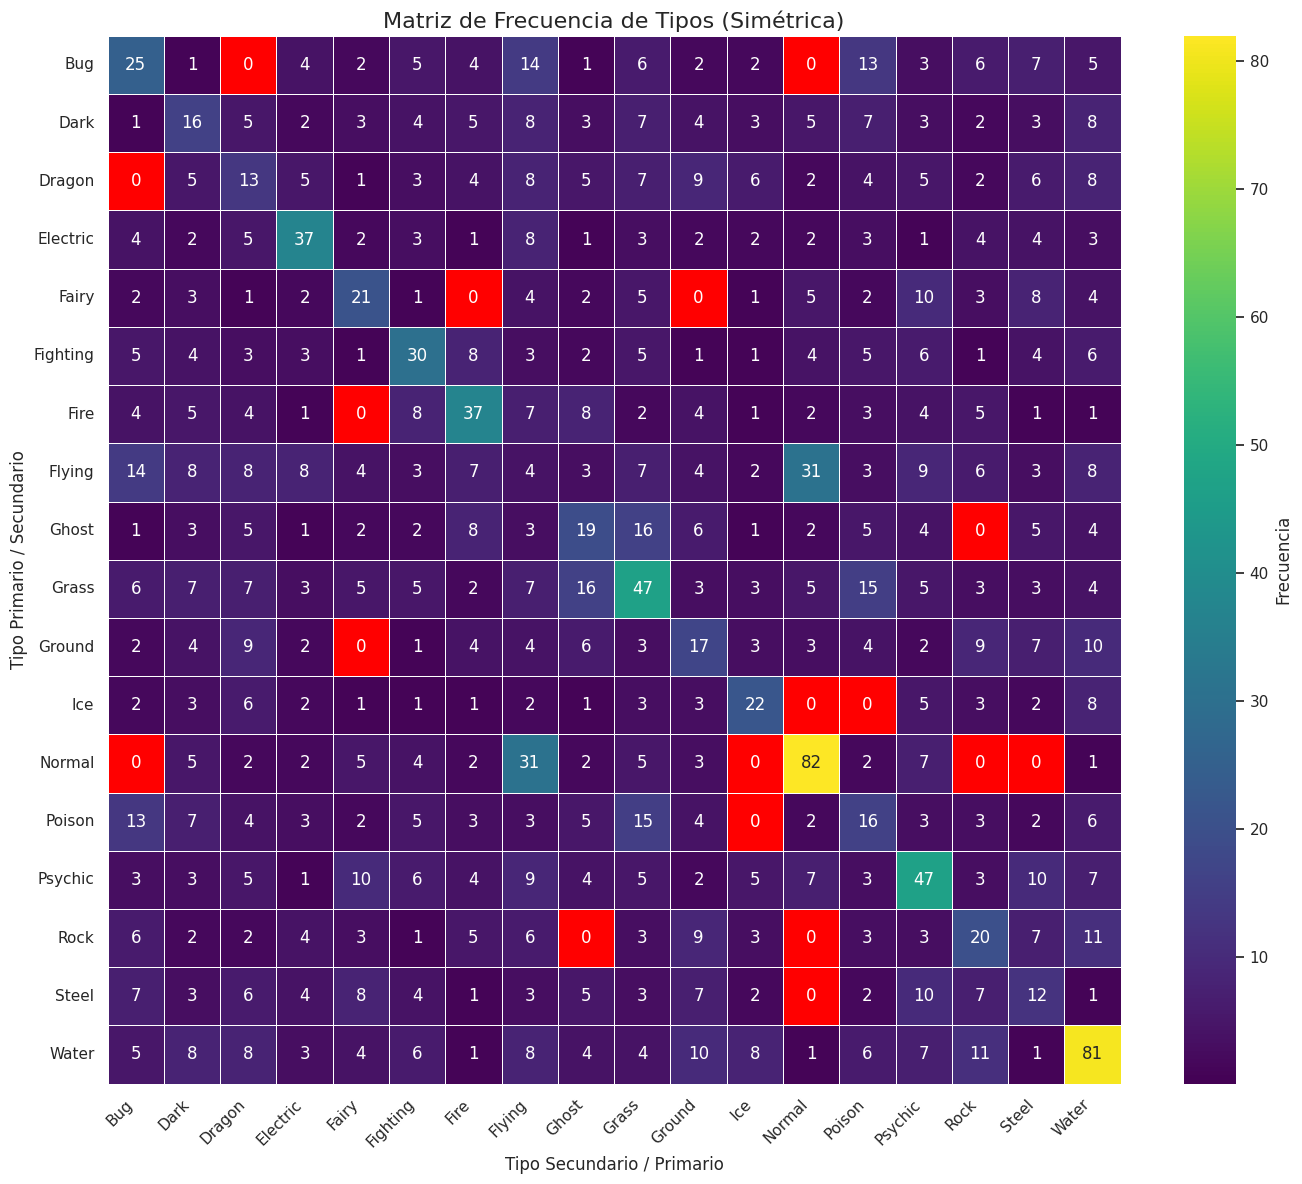


Type Individual (Total apariciones):
Water               :176
Normal              :153
Grass               :146
Psychic             :134
Flying              :132
Bug                 :100
Fire                :97 
Poison              :96 
Dragon              :93 
Fighting            :92 
Ground              :90 
Dark                :89 
Rock                :88 
Electric            :87 
Ghost               :87 
Steel               :85 
Fairy               :74 
Ice                 :65 


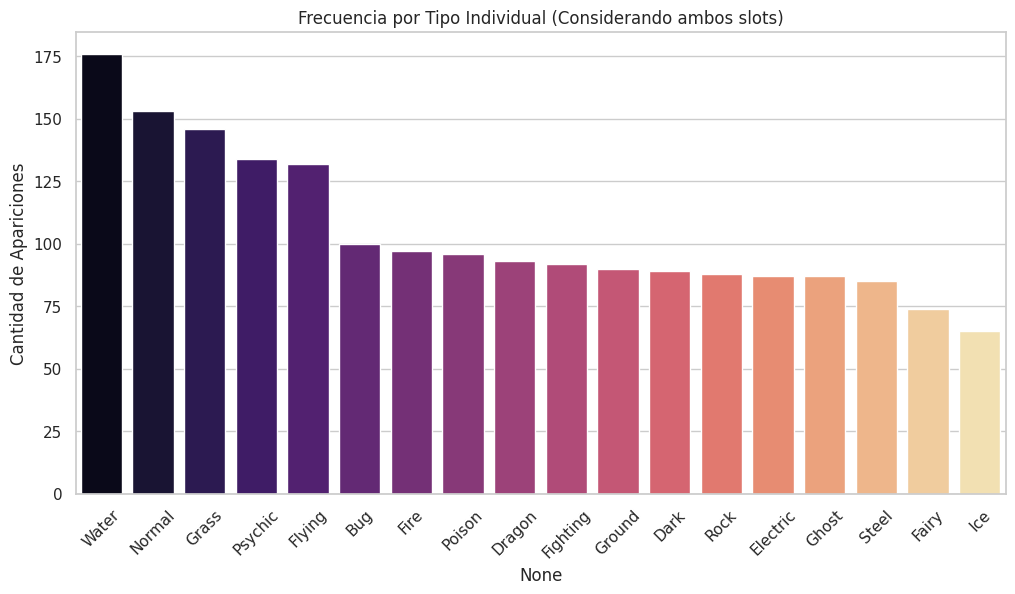

In [ ]:
"""
No generado LLM

Analisis estadistico de los datos categoricos.

Para los doble tipos se crea un heatmap señalando con los rojos los casos no conocidos de combinaciones.

A parte se crea un grafico de barras de los tipos individuales. Estos consideran que si un pokemon es de doble sume una unidad en cada uno de los tipos
"""

def analyze_categorical_frequencies(df):
    """
    Analiza frecuencias de Type Joint (Heatmap simétrico) y Tipos Individuales.
    """
    print("\n--- 3. ANÁLISIS CATEGÓRICO (FRECUENCIAS) ---")

    # --- A. Análisis por Type Joint (HEATMAP SIMÉTRICO) ---

    # 1. Preparación de datos para la Simetría
    type_pairs = []

    for _, row in df.iterrows():
        t1 = row['Type 1']
        t2 = row['Type 2']

        # Verificamos si Type 2 existe (no es nulo ni vacío)
        has_t2 = pd.notna(t2) and t2 != ''

        if has_t2:
            # Pokémon de tipo doble: contamos en AMBOS sentidos
            # Esto cumple tu requisito: Planta/Veneno cuenta en [Planta, Veneno] y [Veneno, Planta]
            type_pairs.append({'Row': t1, 'Col': t2})
            type_pairs.append({'Row': t2, 'Col': t1})
        else:
            # Pokémon de tipo puro: cuenta en la diagonal (ej. Fuego, Fuego)
            type_pairs.append({'Row': t1, 'Col': t1})

    # 2. Crear DataFrame temporal y Matriz
    df_heatmap = pd.DataFrame(type_pairs)
    matrix = pd.crosstab(df_heatmap['Row'], df_heatmap['Col'])

    # Ordenar alfabéticamente para que el gráfico sea cuadrado y ordenado
    all_types_sorted = sorted(list(set(matrix.index) | set(matrix.columns)))
    matrix = matrix.reindex(index=all_types_sorted, columns=all_types_sorted, fill_value=0)

    # 1. Copiamos la paleta viridis para no modificar la original del sistema
    custom_cmap = copy.copy(plt.cm.get_cmap('viridis'))

    # 2. Definimos que los valores "por debajo" del mínimo (under) sean ROJOS
    custom_cmap.set_under('red')

    # 3. Graficar Heatmap
    plt.figure(figsize=(14, 12))
    sns.heatmap(
        matrix,
        annot=True,         # Muestra los números
        fmt='d',            # Formato entero
        cmap=custom_cmap,     # Escala de colores
        vmin=0.1,           # Valores menores a 0.1 se marcan en rojo. Solo el 0
        linewidths=.5,      # Líneas blancas entre celdas
        cbar_kws={'label': 'Frecuencia'}
    )

    plt.title('Matriz de Frecuencia de Tipos (Simétrica)', fontsize=16)
    plt.xlabel('Tipo Secundario / Primario')
    plt.ylabel('Tipo Primario / Secundario')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # --- B. Análisis por Tipo Individual (INTACTO) ---
    # Concatenamos Type 1 y Type 2 en una sola serie
    all_types = pd.concat([df['Type 1'], df['Type 2']]).dropna()
    # Filtramos strings vacíos si los hubiera
    all_types = all_types[all_types != '']

    print("\nType Individual (Total apariciones):")
    for tipo, valor in all_types.value_counts().items():
        print(f"{tipo:<20}:{valor:<3}")

    plt.figure(figsize=(12, 6))
    type_counts = all_types.value_counts()
    sns.barplot(x=type_counts.index, y=type_counts.values, palette='magma')
    plt.xticks(rotation=45)
    plt.title('Frecuencia por Tipo Individual (Considerando ambos slots)')
    plt.ylabel('Cantidad de Apariciones')
    plt.show()

# Ejemplo de uso:
analyze_categorical_frequencies(df_pokemon)

### Observacion 2

Hay 17 combinaciones de dos tipos que no tienen actual representacion, esto puede ayudar a la empresa que tiene pendientes por diseñar por ejemplo Fairy y Fire, el Fairy usualmente se basa en eventos fantasiosos y el fuego que asimila el calor.

En el analisis individual nos dice que el tipo agua asi como en la naturaleza es donde hay mas diversidad, mientras el tipo hielo es el menos diverso casi siendo la tercera parte del tipo agua o normal.


--- 4. MATRIZ DE CORRELACIÓN ---


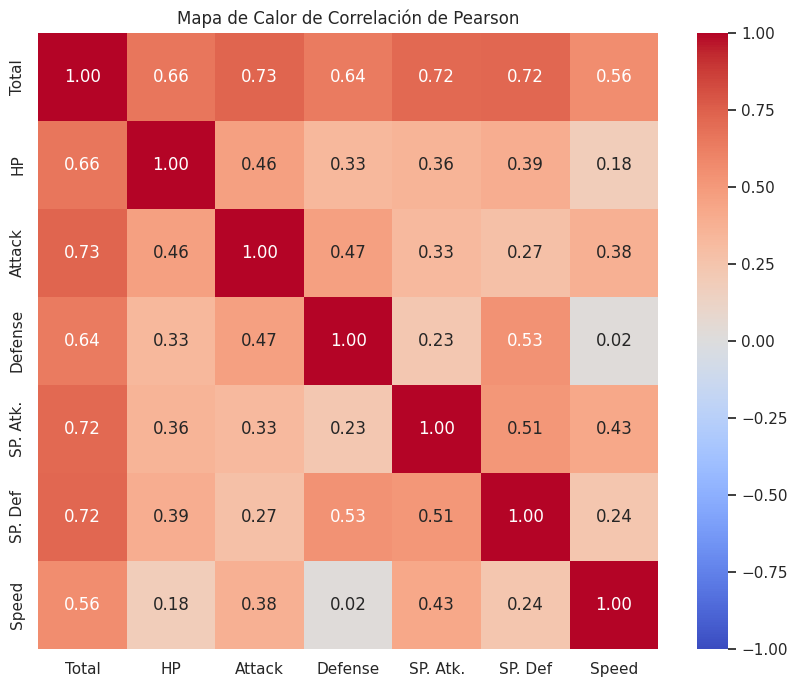

In [ ]:
"""
No generado LLM

Matriz de correlación de las estadisticas

"""

def analyze_correlations(df):
    """
    Matriz de correlación de variables numéricas.
    """
    print("\n--- 4. MATRIZ DE CORRELACIÓN ---")
    numeric_df = df.select_dtypes(include=[np.number])
    corr_matrix = numeric_df.corr()

    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
    plt.title('Mapa de Calor de Correlación de Pearson')
    plt.show()

# 4. Correlación
analyze_correlations(df_pokemon)

### Observacion 3

El Total al ser la suma de las 6 estadisticas, el comportamiento de >0.55 en el resto, es completamente esperable, lo que es coincidencia y visible de ver es lo poco que se relaciona la velocidad con el resto de estadisticas, siendo la mas variable la defensa donde no hay una correlación lineal de estos.


--- 5. BOXPLOTS CRUZADOS POR TIPO ---


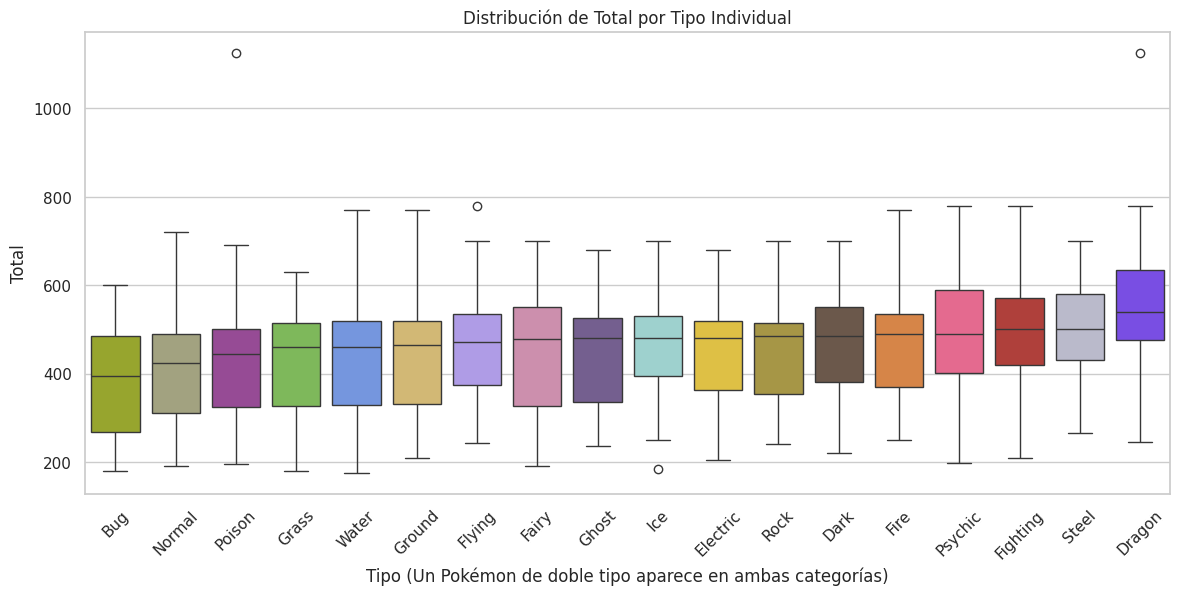

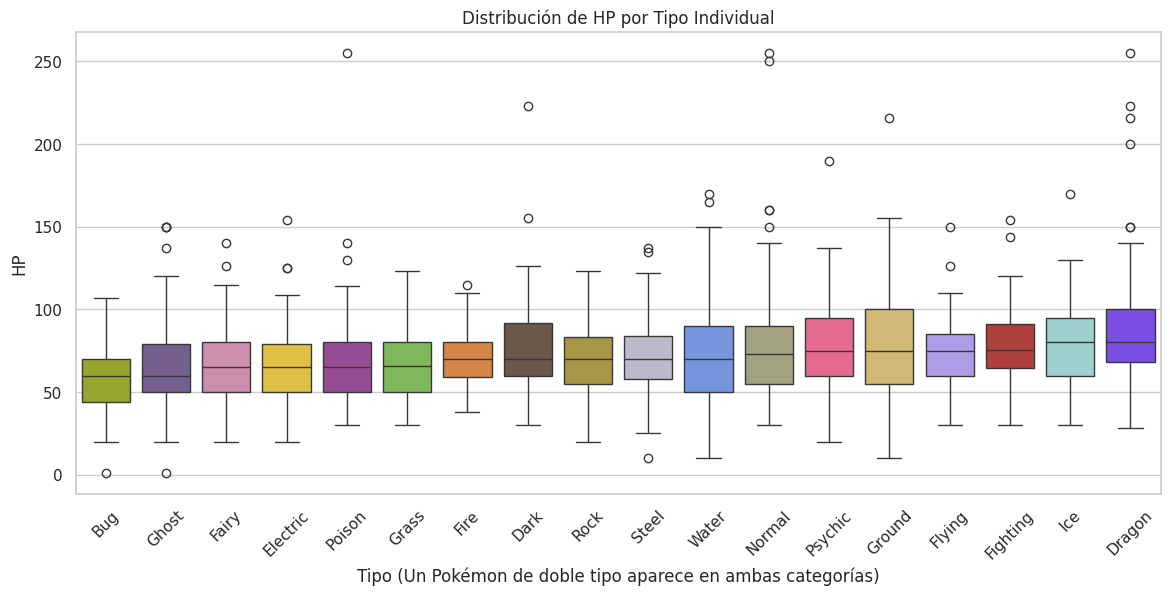

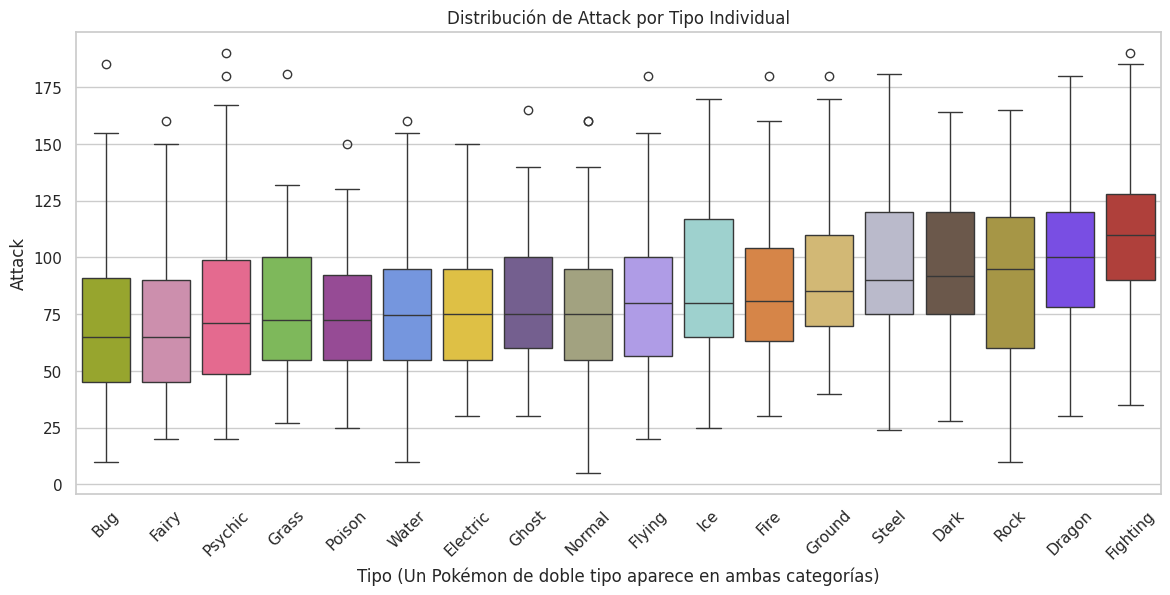

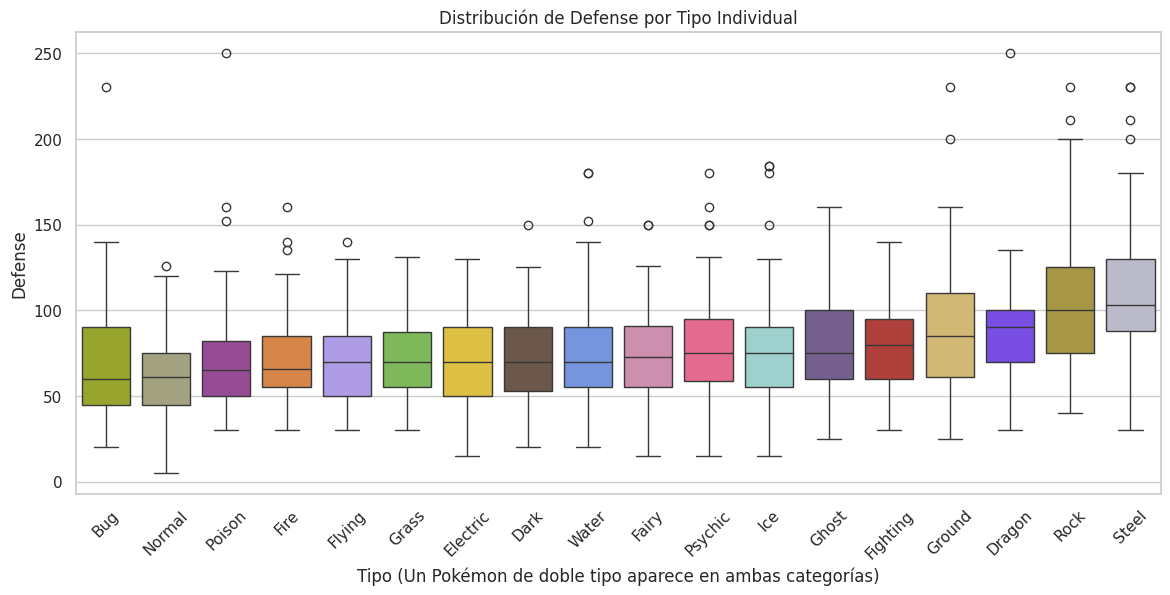

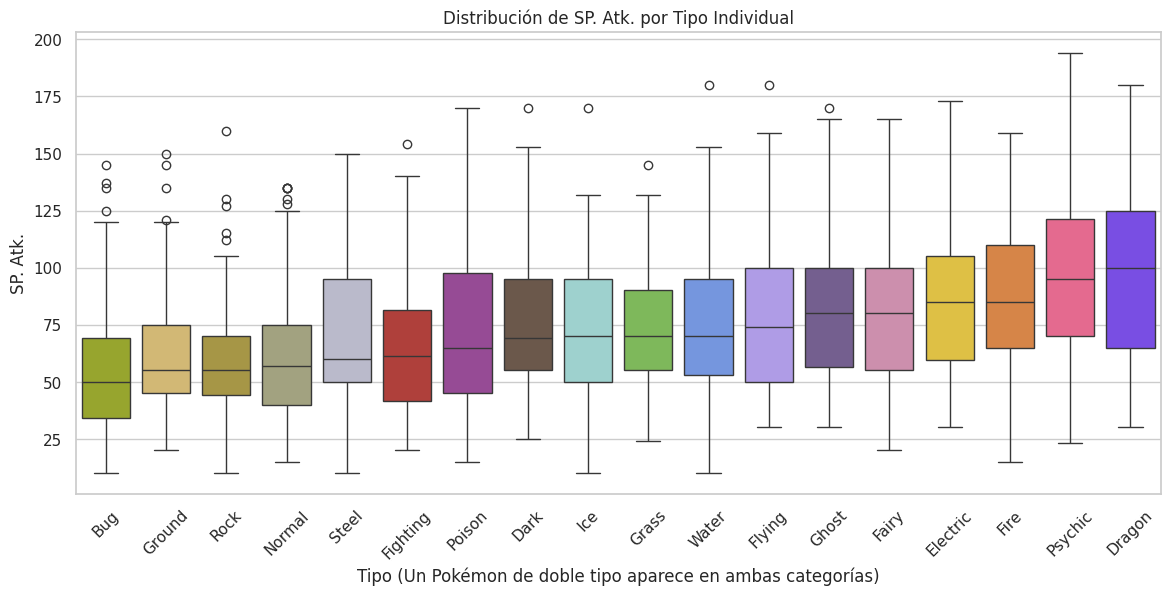

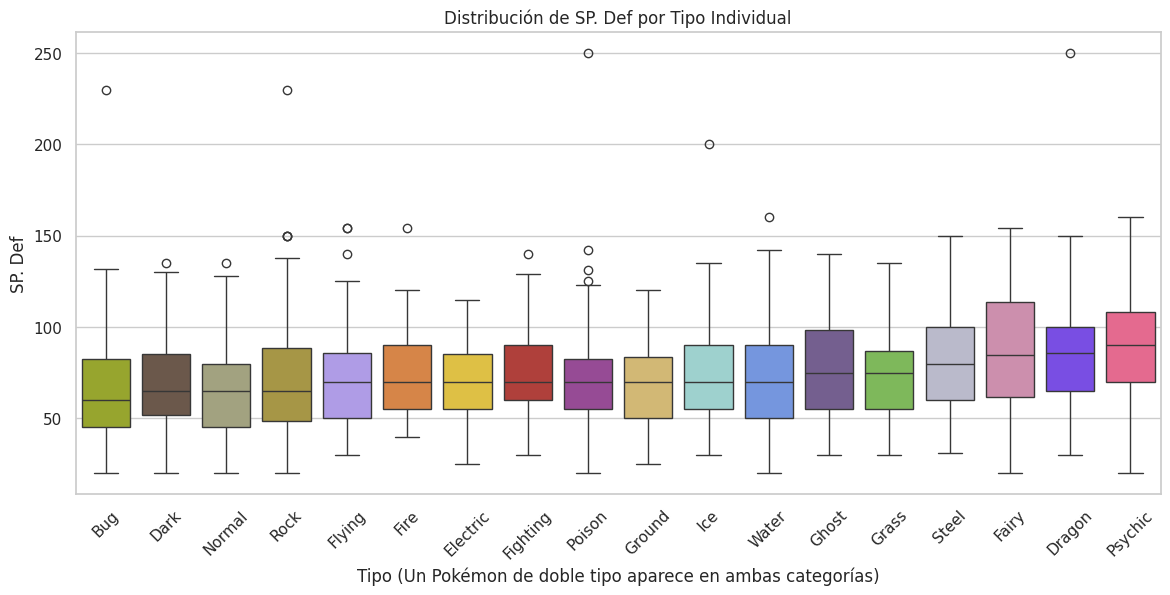

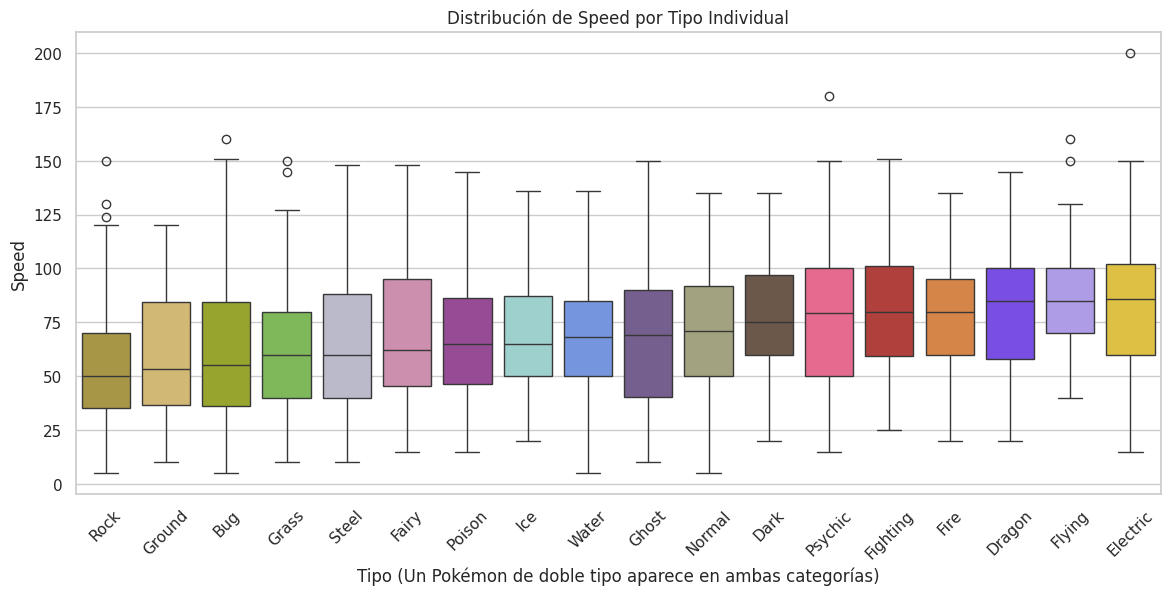

In [ ]:
"""
No generado LLM

Boxplots que visualizan como se comportan las estadisticas para cada tipo de Pokemon.

Busqueda de saber que tipo es mejor, peor o se mantienen en la media para cada una de las caracteristicas.

"""

def analyze_boxplots_cross_types(df):
    """
    Genera Boxplots donde un Pokémon con doble tipo aparece en AMBAS categorías.
    """
    print("\n--- 5. BOXPLOTS CRUZADOS POR TIPO ---")

    numeric_cols = df.select_dtypes(include=[np.number]).columns

    # Transformación de datos: "Melting" para duplicar filas de tipos dobles
    # Esto permite que un Bulbasaur cuente para 'Grass' y para 'Poison'
    df_long = df.melt(id_vars=numeric_cols, value_vars=['Type 1', 'Type 2'],
                      value_name='Type_Split').dropna(subset=['Type_Split'])

    # Graficar
    num_plots = len(numeric_cols)
    # Haremos gráficos grandes individuales porque hay muchos tipos

    colores_dict = {
        "Normal": "#A8A77A",
        "Fighting": "#C22E28",
        "Flying": "#A98FF3",
        "Poison": "#A33EA1",
        "Ground": "#E2BF65",
        "Rock": "#B6A136",
        "Bug": "#A6B91A",
        "Ghost": "#735797",
        "Steel": "#B7B7CE",
        "Fire": "#EE8130",
        "Water": "#6390F0",
        "Grass": "#7AC74C",
        "Electric": "#F7D02C",
        "Psychic": "#F95587",
        "Ice": "#96D9D6",
        "Dragon": "#6F35FC",
        "Dark": "#705746",
        "Fairy": "#D685AD"
    }

    for col in numeric_cols:
        plt.figure(figsize=(14, 6))

        # Ordenar por mediana para mejor visualización
        order = df_long.groupby('Type_Split')[col].median().sort_values().index

        sns.boxplot(data=df_long, x='Type_Split', y=col, order=order, palette=colores_dict)
        plt.title(f'Distribución de {col} por Tipo Individual')
        plt.xticks(rotation=45)
        plt.xlabel('Tipo (Un Pokémon de doble tipo aparece en ambas categorías)')
        plt.show()

# 5. Boxplots Cruzados
analyze_boxplots_cross_types(df_pokemon)

### Observacion 4

El tipo bicho en general es el peor. Solo en velocidad la roca y la tierra que suele ser lo mas pesado posee velocidad menor que la del bicho.

Mientras el top 1 de cada estadistica son

* Total: Dragon
* HP: Dragon
* Ataque Fisico: Lucha
* Defensa: Acero
* Araque Especial: Dragon
* Defensa Especial: Psiquico
* Velocidad: Electrico

Con respecto a outliers.

La estadistica Total, al ser casi una distribucion justa, al ser un juego de competitiva, tiene muy pocos casos.

Pero mientras tanto la estadistica HP es la que tiene Outliers más exagerados y fuertemente influenciados por la fase, detalle que el df debe mejorar.

# Entrenamiento

In [8]:
"""
No generado LLM

Creacion de la clase Pokemon e integracion de la imagen a cada uno de estos

"""

# --- 1. DATASET DE TIPOS ---
class PokemonTypeDataset(Dataset):
    def __init__(self, excel_file, root_dir, transform=None):
        self.df = pd.read_excel(excel_file)
        self.root_dir = root_dir
        self.transform = transform

        # OBTENER CLASES DE TIPOS
        # Usamos 'Type 1' como la etiqueta principal
        self.classes = sorted(self.df['Type 1'].unique())
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)}
        self.idx_to_class = {i: cls_name for cls_name, i in self.class_to_idx.items()}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # Cargar Imagen
        img_path = os.path.join(self.root_dir, self.df.iloc[idx, 0])
        try:
            image = Image.open(img_path).convert('RGB')
        except:
            image = Image.new('RGB', (224, 224), (0, 0, 0)) # Fallback negro

        # Cargar Etiqueta (Tipo)
        type_name = self.df.iloc[idx, 3] # Columna 'Type 1'
        label = self.class_to_idx[type_name]

        if self.transform:
            image = self.transform(image)

        return image, label

In [9]:
"""
No generado LLM

Transformaciones que se aplicaran a la imagen para su entrenamiento.

"""


# Transformaciones
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomAffine(degrees=20, translate=(0.1, 0.1), scale=(0.9, 1.1)), # Augmentation
        transforms.RandomHorizontalFlip(),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

In [10]:
"""
No generado LLM

Se decide usar el total del dataset al poseer representantes de dos tipos que solo tienen 1 y queremos evitar falto de información por el azar.

Y para la validacion el 40% de los datos

"""

# --- 2. PREPARACIÓN DE DATOS (TRAIN 100% / VAL 40%) ---
# Instancias
train_dataset = PokemonTypeDataset(EXCEL_FILE, IMG_DIR, transform=data_transforms['train'])
val_base_dataset = PokemonTypeDataset(EXCEL_FILE, IMG_DIR, transform=data_transforms['val'])

# Crear Subset aleatorio del 40% para validación
indices = list(range(len(train_dataset)))
val_indices = random.sample(indices, int(len(indices) * 0.4))
val_dataset = Subset(val_base_dataset, val_indices)

# Dataloaders
dataloaders = {
    'train': DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2),
    'val': DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
}

dataset_sizes = {'train': len(train_dataset), 'val': len(val_dataset)}
class_names = train_dataset.classes # Lista de tipos (Agua, Fuego, etc.)

print(f"Tipos a predecir: {class_names}")

Tipos a predecir: ['Bug', 'Dark', 'Dragon', 'Electric', 'Fairy', 'Fighting', 'Fire', 'Flying', 'Ghost', 'Grass', 'Ground', 'Ice', 'Normal', 'Poison', 'Psychic', 'Rock', 'Steel', 'Water']


In [ ]:
"""
No generado LLM

Red neuronal convolucional con las librerias resnet y optimizador Adam.

Generacion del modelo best_pokemon_type_model.pth, entregable

"""

# --- 3. MODELO Y ENTRENAMIENTO ---
def train_type_model(num_epochs=15):
    # Cargar ResNet
    model = models.resnet18(pretrained=True)

    # ESTRATEGIA: Descongelar para ajustar colores/formas a tipos
    for param in model.parameters():
        param.requires_grad = True

    # Cambiar capa final para 18 Tipos
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, len(class_names))
    model = model.to(DEVICE)

    # Optimizador y Loss
    criterion = nn.CrossEntropyLoss()
    # Learning Rate bajo para no destruir lo aprendido, un poco más alto en la capa final
    optimizer = optim.Adam([
        {'params': list(model.parameters())[:-2], 'lr': 1e-5}, # Cuerpo CNN
        {'params': model.fc.parameters(), 'lr': 1e-3}          # Cabezal Clasificador
    ])

    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

    # Bucle
    since = time.time()
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(DEVICE)
                labels = labels.to(DEVICE)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                # Guardamos el mejor modelo
                torch.save(model.state_dict(), 'best_pokemon_type_model.pth')

        scheduler.step()
        print()

    print(f'Mejor Val Acc: {best_acc:4f}')

    # Cargar mejor peso
    model.load_state_dict(torch.load('best_pokemon_type_model.pth'))
    return model


In [ ]:
"""
No generado LLM

No hacer si se posee el archivo: 'best_pokemon_type_model.pth'

Inicio de Entrenamiento, duracion casi 20 minutos, al ser mas de 1000 imagenes

"""
model_tipos = train_type_model(num_epochs=NUM_EPOCHS)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 118MB/s]


Epoch 0/3
----------
train Loss: 2.8027 Acc: 0.1284
val Loss: 2.6200 Acc: 0.1811

Epoch 1/3
----------
train Loss: 2.5030 Acc: 0.2337
val Loss: 2.5098 Acc: 0.2037

Epoch 2/3
----------
train Loss: 2.3140 Acc: 0.2889
val Loss: 2.2556 Acc: 0.3004

Epoch 3/3
----------
train Loss: 2.1635 Acc: 0.3366
val Loss: 2.0947 Acc: 0.3107

Mejor Val Acc: 0.310700


##Para recargar el modelo

In [11]:
"""
No generado LLM

Si se tiene el modelo 'best_pokemon_type_model.pth', y no perder tiempo, cargarloi aca.

"""

def cargar_modelo(path, num_classes, device):
    print(f"Cargando modelo desde {path}...")

    # 1. Recrear arquitectura (Ajusta esto si usaste otro modelo como EfficientNet)
    model = models.resnet18(pretrained=False)
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, num_classes)

    # 2. Cargar pesos
    try:
        # map_location asegura que funcione aunque no tengas GPU ahora
        state_dict = torch.load(path, map_location=device)
        model.load_state_dict(state_dict)
    except Exception as e:
        print(f"Error cargando pesos: {e}")
        return None

    # 3. Enviar a dispositivo y modo eval
    model = model.to(device)
    model.eval()

    return model

model_tipos=cargar_modelo('best_pokemon_type_model.pth', len(class_names), DEVICE)

Cargando modelo desde best_pokemon_type_model.pth...


# Creacion de Minijuegos

## Minijuego 1. Adivina el tipo del Pokemon

In [17]:
"""
No generado LLM

Explicacion del juego

1. Usa el archivo Podedex.xlsx y busca al azar el nombre de un Pokemon
2. Lo busca en Web y muestra la primera imagen encontrada
3. Le da 4 opciones al jugador contra la IA y que adivine. 1 correcta y las otras 3 son distractores.
4. El jugador da su respuesta y la IA predice usando la imagen provista con las 4 opciones.
4.1 Analisis de IA cerrado, indica propabilidades con las 4 opciones dadas es decir el 100% son las 4 opciones.
4.2 Provee e top 3 e intenta adivinar el tipo.
5. Se da al ganador al Usuario si acierta o a la IA si acierta en el Top 3.

Objetivo: Dado el modelo encerrar entre posibilidades. Posible uso a futuro en el campo de Medicina cuando se tenga dudas entre opciones y no buscar una respuesta general es posible ser más preciso al dar una respuesta.

"""


# --- A. FUNCIÓN AUXILIAR PARA BUSCAR EN BING ---
def buscar_imagen_bing(query):
    """
    Busca una imagen en Bing y retorna la URL directa de la primera coincidencia.
    Usa headers para simular ser un navegador real y evitar bloqueos.
    """
    url = "https://www.bing.com/images/search"
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3"
    }
    params = {"q": query, "first": 1} # 'first': 1 intenta priorizar el primer resultado

    try:
        response = requests.get(url, params=params, headers=headers)
        response.raise_for_status()

        # Bing guarda las URLs de las imágenes originales dentro del código fuente
        # bajo el patrón "murl":"URL". Usamos Regex para capturarlo.
        # Buscamos la primera ocurrencia de 'murl'
        match = re.search(r'murl&quot;:&quot;(.*?)&quot;', response.text)

        if match:
            return match.group(1) # Retorna la URL limpia
        else:
            return None
    except Exception as e:
        print(f"Error buscando en Bing: {e}")
        return None

# --- B. MINIJUEGO DE TIPOS (MODIFICADO) ---
def jugar_ronda_restringida(model, df_original, class_names, class_to_idx):

    # --- 1. PREPARAR LA RONDA ---
    # Elegir Pokémon al azar
    target = df_original.sample(1).iloc[0]
    nombre_pokemon = target['Name']

    print(f"🔎 Buscando imagen de {nombre_pokemon} en Bing...")

    # --- CAMBIO CLAVE: BÚSQUEDA WEB ---
    # Generamos una búsqueda específica (ej: "Pikachu official artwork pokemon")
    query_busqueda = f"{nombre_pokemon} pokemon official art"
    img_url = buscar_imagen_bing(query_busqueda)

    img = None
    if img_url:
        try:
            # Descargamos la imagen de la URL encontrada
            response_img = requests.get(img_url, timeout=5)
            img = Image.open(BytesIO(response_img.content)).convert('RGB')
        except Exception as e:
            print(f"⚠️ No se pudo descargar la imagen desde la URL encontrada. Error: {e}")

    # Si falló la búsqueda o la descarga, usamos un placeholder o cancelamos
    if img is None:
        print("❌ No se encontró imagen válida. Saltando ronda.")
        return
    # ----------------------------------

    # Tipos correctos (Lógica original)
    tipos_correctos = {target['Type 1'], target['Type 2']} - {float('nan')}
    tipo_principal = target['Type 1']

    # Generar opciones (1 Correcta + 3 Distractores)
    todas_opciones = set(class_names)
    distractores = list(todas_opciones - tipos_correctos)
    opciones_juego = [tipo_principal] + random.sample(distractores, 3)
    random.shuffle(opciones_juego)

    # --- 2. MOSTRAR AL USUARIO ---
    plt.figure(figsize=(4,4))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"¿De qué tipo es {nombre_pokemon}?")
    plt.show()

    print(f"\n⚡ Misión: Adivina el TIPO de {nombre_pokemon}")
    letras = ['A', 'B', 'C', 'D']
    mapa_opciones = {l: opt for l, opt in zip(letras, opciones_juego)}

    for l in letras:
        print(f"  {l}) {mapa_opciones[l]}")

    # Pequeña pausa para dar emoción
    sleep(1)
    seleccion = input("\nTu respuesta (A/B/C/D): ").upper()
    while seleccion not in letras:
        seleccion = input("Opción inválida (A/B/C/D): ").upper()
    usuario_tipo = mapa_opciones[seleccion]

    # --- 3. CEREBRO DE LA IA (MODO RESTRINGIDO) ---
    print("\n🧠 La IA analiza la imagen descargada...")


    # Procesar imagen (Asegúrate de que 'data_transforms' y 'DEVICE' estén definidos en tu notebook)
    # Nota: transform_val debe ser tu transformación de validación (Resize -> Tensor -> Normalize)
    transform_val = data_transforms['val']
    img_tensor = transform_val(img).unsqueeze(0).to(DEVICE)

    model.eval()
    with torch.no_grad():
        # 1. Logits completos
        logits_completos = model(img_tensor)

        # 2. FILTRADO: Extraemos solo los puntajes de las 4 opciones
        indices_opciones = [class_to_idx[nombre] for nombre in opciones_juego]
        indices_tensor = torch.tensor(indices_opciones).to(DEVICE)

        logits_restringidos = logits_completos[0, indices_tensor]

        # 3. RE-NORMALIZACIÓN (Softmax restringido)
        probs_restringidas = F.softmax(logits_restringidos, dim=0)

        # 4. RANKING
        top3_probs, top3_indices_relativos = torch.topk(probs_restringidas, 3)

    # --- 4. RESULTADOS ---
    print("-" * 40)
    print(f"REALIDAD: {nombre_pokemon} es {', '.join([str(t) for t in tipos_correctos])}")
    print("-" * 40)

    # Resultado Usuario
    if usuario_tipo in tipos_correctos:
        print(f"👤 TÚ: ✅ ¡Acertaste!")
    else:
        print(f"👤 TÚ: ❌ Fallaste (Elegiste {usuario_tipo})")

    # Resultado IA
    print("\n🤖 LA IA DICE (Entre las opciones dadas):")
    ia_gano = False

    for i in range(3):
        idx_relativo = top3_indices_relativos[i].item()
        nombre_opcion = opciones_juego[idx_relativo]
        confianza = top3_probs[i].item()

        es_correcto = nombre_opcion in tipos_correctos
        icono = "✅" if es_correcto else "❌"
        if es_correcto: ia_gano = True

        print(f"   Opción #{i+1}: {nombre_opcion:10s} (Probabilidad relativa: {confianza:.1%}) {icono}")

    if ia_gano:
        print("\n🏆 La IA encontró la respuesta correcta.")
    else:
        print("\n💀 La IA fue engañada por los distractores.")


df_full = pd.read_excel('pokedex.xlsx')


¿Cuántas veces quieres jugar? 3
🔎 Buscando imagen de Dudunsparce Three-Segment Form en Bing...


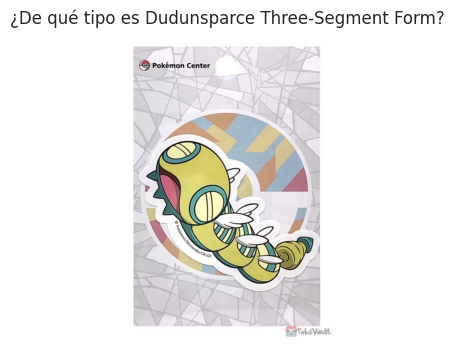


⚡ Misión: Adivina el TIPO de Dudunsparce Three-Segment Form
  A) Poison
  B) Normal
  C) Dragon
  D) Ice

Tu respuesta (A/B/C/D): B

🧠 La IA analiza la imagen descargada...
----------------------------------------
REALIDAD: Dudunsparce Three-Segment Form es Normal, nan
----------------------------------------
👤 TÚ: ✅ ¡Acertaste!

🤖 LA IA DICE (Entre las opciones dadas):
   Opción #1: Normal     (Probabilidad relativa: 48.3%) ✅
   Opción #2: Ice        (Probabilidad relativa: 30.8%) ❌
   Opción #3: Dragon     (Probabilidad relativa: 17.8%) ❌

🏆 La IA encontró la respuesta correcta.
🔎 Buscando imagen de Weavile en Bing...


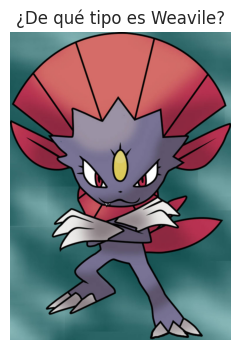


⚡ Misión: Adivina el TIPO de Weavile
  A) Electric
  B) Dark
  C) Fighting
  D) Normal

Tu respuesta (A/B/C/D): B

🧠 La IA analiza la imagen descargada...
----------------------------------------
REALIDAD: Weavile es Ice, Dark
----------------------------------------
👤 TÚ: ✅ ¡Acertaste!

🤖 LA IA DICE (Entre las opciones dadas):
   Opción #1: Electric   (Probabilidad relativa: 40.7%) ❌
   Opción #2: Normal     (Probabilidad relativa: 36.1%) ❌
   Opción #3: Fighting   (Probabilidad relativa: 12.1%) ❌

💀 La IA fue engañada por los distractores.
🔎 Buscando imagen de Crawdaunt en Bing...


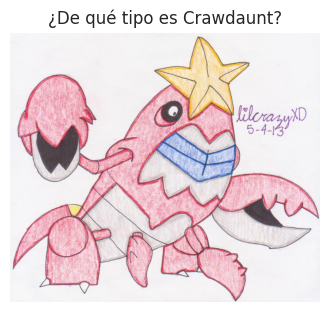


⚡ Misión: Adivina el TIPO de Crawdaunt
  A) Ghost
  B) Water
  C) Ice
  D) Electric

Tu respuesta (A/B/C/D): B

🧠 La IA analiza la imagen descargada...
----------------------------------------
REALIDAD: Crawdaunt es Dark, Water
----------------------------------------
👤 TÚ: ✅ ¡Acertaste!

🤖 LA IA DICE (Entre las opciones dadas):
   Opción #1: Ice        (Probabilidad relativa: 58.1%) ❌
   Opción #2: Electric   (Probabilidad relativa: 26.4%) ❌
   Opción #3: Water      (Probabilidad relativa: 12.3%) ✅

🏆 La IA encontró la respuesta correcta.


In [19]:
def es_numero_entero_positivo(valor):
    try:
        numero = int(valor)
        return numero > 0
    except ValueError:
        return False

jugadas = ""
while not(es_numero_entero_positivo(jugadas)):
    jugadas = int(input("¿Cuántas veces quieres jugar? "))
    try:
      for _ in range(jugadas):
          jugar_ronda_restringida(model_tipos, df_full, train_dataset.classes, train_dataset.class_to_idx)
    except ValueError:
      print("Por favor ingresa un número entero positivo.")


## Minijuego 2. Adivina el Pokemon según el tipo

In [28]:
"""
No generado LLM

Explicacion del juego Inverso con version online (Independencia de Imagenes)

1. Usa la lista de clases de tipos de Pokemon y busca al azar un Pokemon de ese tipo, es decir la opcion correcta
2. Se colocan tres distractores, si alguno de ellos si posee el tipo correcto se vuelven a barajar los distractores
3. Le da 4 opciones al jugador contra la IA y que adivine. 1 correcta y las otras 3 son distractores.
4. El jugador puede dar su respuesta o visualizar ese Pokemon, luego la IA procesa las 4 imagenes y provee el rango de confianza que posee ese Pokemon con el tipo escrito.
4.1 Analisis de IA abierto, toma cada imagen y obtiene las probabilidades de todos los 18 tipos.
4.2 Con el porcentaje de confianza del tipo en cuestion, coloca un Top 3 y se visualiza a ver si su prediccion es correcta o ni con tres posibilidades lo logra
5. Se da al ganador al Usuario si acierta o a la IA si acierta en el Top 3.

Objetivo: Al dar la posibilidad de dar mas de una imagen de analizar y ver su estado de confianza es posible analizar en futuros proyectos como indicaciones de tendencía y valorar cada opción de forma independiente y poder hacer una comparativa de cada una.
En el area de la fisíca el algoritmo puede ayudar a determinar la confianza de una ecuacion sobre otra en un mismo problema y calcular el error de cada una. ejemplo validar si la gravedad en un sitio es 9.81 m/s2 o si eiste una mejor ecuación que la simule.

"""

def buscar_imagen_bing(query):
    url = "https://www.bing.com/images/search"
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3"
    }
    params = {"q": query, "first": 1}
    try:
        response = requests.get(url, params=params, headers=headers)
        response.raise_for_status()
        match = re.search(r'murl&quot;:&quot;(.*?)&quot;', response.text)
        return match.group(1) if match else None
    except Exception as e:
        print(f"Error buscando en Bing: {e}")
        return None

def descargar_imagen(url):
    try:
        response = requests.get(url, timeout=5)
        img = Image.open(BytesIO(response.content)).convert('RGB')
        return img
    except:
        return None

def jugar_ronda_inversa_online(model, df_original, class_names, class_to_idx, transform):
    """
    Juego Inverso usando imágenes de Internet.
    """
    print("\n" + "="*50)
    print("🎲 NUEVA RONDA: 'POKÉMON WEB SEARCH' 🎲")
    print("="*50)

    target_type = random.choice(class_names)
    idx_target_type = class_to_idx[target_type]

    df_clean = df_original.copy()
    df_clean['Type 2'] = df_clean['Type 2'].fillna('')

    pool_correctos = df_clean[(df_clean['Type 1'] == target_type) | (df_clean['Type 2'] == target_type)]
    if len(pool_correctos) == 0: return

    correcto = pool_correctos.sample(1).iloc[0]
    distractores = df_clean[(df_clean['Type 1'] != target_type) & (df_clean['Type 2'] != target_type)].sample(3)

    opciones = [correcto] + [d for _, d in distractores.iterrows()]
    random.shuffle(opciones)

    indice_ganador = next(i+1 for i, opt in enumerate(opciones) if opt['Name'] == correcto['Name'])

    # --- 1. PRE-CARGA DE IMÁGENES DESDE INTERNET ---
    print(f"\n🔎 BUSCAMOS UN TIPO: ✨ {target_type.upper()} ✨")
    print("🌐 Descargando imágenes de la web...")

    imagenes_pil = []
    for opt in opciones:
        url = buscar_imagen_bing(f"{opt['Name']}")
        img = descargar_imagen(url) if url else None
        imagenes_pil.append(img)

    for i in range(4):
        status = "✅ Lista" if imagenes_pil[i] else "❌ Error de carga"
        print(f"   [{i+1}] {opciones[i]['Name']} ({status})")

    # --- 2. BUCLE DE INTERACCIÓN ---
    respuesta_usuario = None
    while True:
        print("\n[1-4] Elegir | [V1-V4] Ver imagen | [Q] Salir")
        sleep(2)
        entrada = input(">> ").strip().upper()

        if entrada == 'Q': return

        if entrada.startswith('V') and len(entrada) > 1:
            idx = int(entrada[1:]) - 1
            if 0 <= idx < 4:
                if imagenes_pil[idx]:
                    plt.figure(figsize=(3,3))
                    plt.imshow(imagenes_pil[idx])
                    plt.title(f"Opción {idx+1}: {opciones[idx]['Name']}")
                    plt.axis('off')
                    plt.show()
                else:
                    print("Imagen no disponible.")
            continue

        if entrada.isdigit() and 1 <= int(entrada) <= 4:
            respuesta_usuario = int(entrada)
            break

    # --- 3. ANÁLISIS DE LA IA CON IMÁGENES DE INTERNET ---
    print(f"\n🧠 La IA analiza las imágenes descargadas...")
    resultados_ia = []
    model.eval()

    with torch.no_grad():
        for i, img in enumerate(imagenes_pil):
            if img:
                img_tensor = transform(img).unsqueeze(0).to(DEVICE)
                logits = model(img_tensor)
                probs = F.softmax(logits, dim=1)[0]
                prob_target = probs[idx_target_type].item()
            else:
                prob_target = 0.0 # Si no cargó la imagen, confianza 0

            resultados_ia.append({
                'opcion': i + 1,
                'prob': prob_target,
                'es_correcto': (i + 1 == indice_ganador),
                'nombre': opciones[i]['Name']
            })

    # --- 4. RESULTADOS ---
    resultados_ia.sort(key=lambda x: x['prob'], reverse=True)

    print("\n" + "-" * 40)
    if respuesta_usuario == indice_ganador:
        print(f"👤 TÚ: ✅ ¡CORRECTO! {opciones[respuesta_usuario-1]['Name']} es tipo {target_type}")
    else:
        print(f"👤 TÚ: ❌ ERROR. La respuesta era {opciones[indice_ganador-1]['Name']}")

    print(f"\n🤖 PREDICCIÓN IA (Tipo {target_type}):")
    for i, res in enumerate(resultados_ia[:3]):
        icono = "⭐" if res['es_correcto'] else ""
        print(f"   #{i+1}: {res['nombre']} ({res['prob']:.1%}) {icono}")

df_full = pd.read_excel('pokedex.xlsx')

¿Cuántas veces quieres jugar? 3

🎲 NUEVA RONDA: 'POKÉMON WEB SEARCH' 🎲

🔎 BUSCAMOS UN TIPO: ✨ FIGHTING ✨
🌐 Descargando imágenes de la web...
   [1] Medicham Mega Medicham (✅ Lista)
   [2] Kingdra (✅ Lista)
   [3] Fuecoco (✅ Lista)
   [4] Druddigon (✅ Lista)

[1-4] Elegir | [V1-V4] Ver imagen | [Q] Salir
>> V1


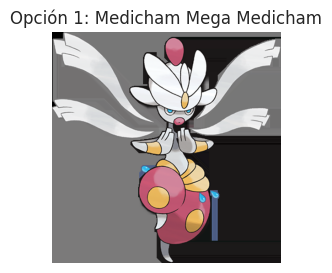


[1-4] Elegir | [V1-V4] Ver imagen | [Q] Salir
>> V2


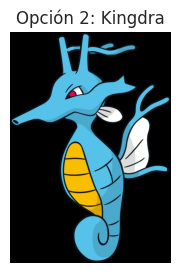


[1-4] Elegir | [V1-V4] Ver imagen | [Q] Salir
>> 1

🧠 La IA analiza las imágenes descargadas...

----------------------------------------
👤 TÚ: ✅ ¡CORRECTO! Medicham Mega Medicham es tipo Fighting

🤖 PREDICCIÓN IA (Tipo Fighting):
   #1: Druddigon (1.3%) 
   #2: Kingdra (1.0%) 
   #3: Medicham Mega Medicham (0.9%) ⭐

🎲 NUEVA RONDA: 'POKÉMON WEB SEARCH' 🎲

🔎 BUSCAMOS UN TIPO: ✨ FLYING ✨
🌐 Descargando imágenes de la web...
   [1] Seaking (✅ Lista)
   [2] Yveltal (✅ Lista)
   [3] Giratina Altered Forme (✅ Lista)
   [4] Musharna (✅ Lista)

[1-4] Elegir | [V1-V4] Ver imagen | [Q] Salir
>> V2


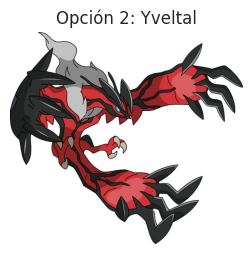


[1-4] Elegir | [V1-V4] Ver imagen | [Q] Salir
>> 2

🧠 La IA analiza las imágenes descargadas...

----------------------------------------
👤 TÚ: ✅ ¡CORRECTO! Yveltal es tipo Flying

🤖 PREDICCIÓN IA (Tipo Flying):
   #1: Musharna (1.2%) 
   #2: Seaking (0.6%) 
   #3: Yveltal (0.3%) ⭐

🎲 NUEVA RONDA: 'POKÉMON WEB SEARCH' 🎲

🔎 BUSCAMOS UN TIPO: ✨ ICE ✨
🌐 Descargando imágenes de la web...
   [1] Cottonee (✅ Lista)
   [2] Muk Alolan Muk (✅ Lista)
   [3] Abomasnow Mega Abomasnow (✅ Lista)
   [4] Venusaur (✅ Lista)

[1-4] Elegir | [V1-V4] Ver imagen | [Q] Salir
>> V3


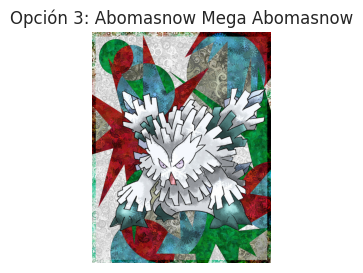


[1-4] Elegir | [V1-V4] Ver imagen | [Q] Salir
>> 3

🧠 La IA analiza las imágenes descargadas...

----------------------------------------
👤 TÚ: ✅ ¡CORRECTO! Abomasnow Mega Abomasnow es tipo Ice

🤖 PREDICCIÓN IA (Tipo Ice):
   #1: Venusaur (3.6%) 
   #2: Cottonee (2.2%) 
   #3: Abomasnow Mega Abomasnow (2.1%) ⭐


In [29]:
def es_numero_entero_positivo(valor):
    try:
        numero = int(valor)
        return numero > 0
    except ValueError:
        return False

jugadas = ""
while not(es_numero_entero_positivo(jugadas)):
    jugadas = int(input("¿Cuántas veces quieres jugar? "))
    try:
      for _ in range(jugadas):
          jugar_ronda_inversa_online(model_tipos, df_full, train_dataset.classes, train_dataset.class_to_idx, data_transforms['val'])
    except ValueError:
      print("Por favor ingresa un número entero positivo.")

## Minijuego 3. Escaner de Aura

In [30]:
"""
No generado LLM

Explicacion del juego escaner de aura

1. Solicita al usuario una imagen en formato de imagen
2. Usa el modelo en su forma más pura analizando las probabilidades de cada tipo en la imagen provista.
3. Ofrece de manera graficada las probabilidades de cada tipo. Dando el top 5 de cada una de estas.
4. Gracias a ello, un diseñador puede validar si la nueva especie es consecuente a lo realizado con anterioridad en generaciones pasadas o si es muy distinto al pensamiento que se tenia.

Objetivo: Al haberse dado un entrenamiento de multiples epocas de manera completa y transformaciones para asegurarnos confianza de las probabilidades y patrones adquiridos por parte del modelo. Posibles aplicaciones analisis de imagenes en redes sociales
como tambien saber si una imagen es adecuada o si se debe aplicar alguna censura por su grado de similitud a ciertos factores: Obsenidad, Religiosidad, Mensajes de Odio.

"""

def escaner_de_aura(model, class_names):
    print("🔮 --- ESCÁNER DE AURA POKÉMON --- 🔮")
    print("Sube una foto de cualquier cosa (tu mascota, comida, tú mismo)...")
    print("El sistema detectará a qué Tipo Pokémon pertenece según sus colores y patrones.")

    # 1. Widget de subida de archivos de Colab
    uploaded = files.upload()

    # Iterar por si subes más de una imagen
    for fn in uploaded.keys():
        # Cargar la imagen desde los bytes subidos
        image_data = uploaded[fn]
        try:
            img = Image.open(io.BytesIO(image_data)).convert('RGB')
        except:
            print(f"No se pudo leer la imagen {fn}")
            continue

        # 2. Preprocesamiento (Igual que en validación)
        transform_val = data_transforms['val']
        img_tensor = transform_val(img).unsqueeze(0).to(DEVICE)

        # 3. Inferencia del Modelo
        model.eval()
        with torch.no_grad():
            logits = model(img_tensor)
            probs = F.softmax(logits, dim=1)

            # Obtener Top 5 Probabilidades
            top5_probs, top5_idxs = torch.topk(probs, 5)

        # 4. Visualización de Resultados
        tipos_detectados = []
        scores = []

        for i in range(5):
            idx = top5_idxs[0][i].item()
            prob = top5_probs[0][i].item()
            tipos_detectados.append(class_names[idx])
            scores.append(prob)

        # Invertimos para que el gráfico de barras muestre el mayor arriba
        tipos_detectados = tipos_detectados[::-1]
        scores = scores[::-1]

        # Crear Gráfico (Imagen + Barras)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

        # Imagen original
        ax1.imshow(img)
        ax1.axis('off')
        ax1.set_title("Tu Imagen")

        # Gráfico de Barras
        bars = ax2.barh(tipos_detectados, scores, color='skyblue')
        # Resaltar la barra ganadora
        bars[-1].set_color('orange')

        ax2.set_xlim(0, 1.0)
        ax2.set_xlabel("Nivel de Resonancia")
        ax2.set_title("Análisis de Aura Elemental")

        # Etiqueta de porcentaje
        for i, v in enumerate(scores):
            ax2.text(v + 0.01, i, f"{v:.1%}", va='center', fontweight='bold')

        plt.tight_layout()
        plt.show()

        print(f"RESULTADO FINAL: ¡Esta imagen tiene alma de tipo {tipos_detectados[-1].upper()}!")
        print("-" * 50)





🔮 --- ESCÁNER DE AURA POKÉMON --- 🔮
Sube una foto de cualquier cosa (tu mascota, comida, tú mismo)...
El sistema detectará a qué Tipo Pokémon pertenece según sus colores y patrones.


Saving agumon.jpg to agumon (2).jpg


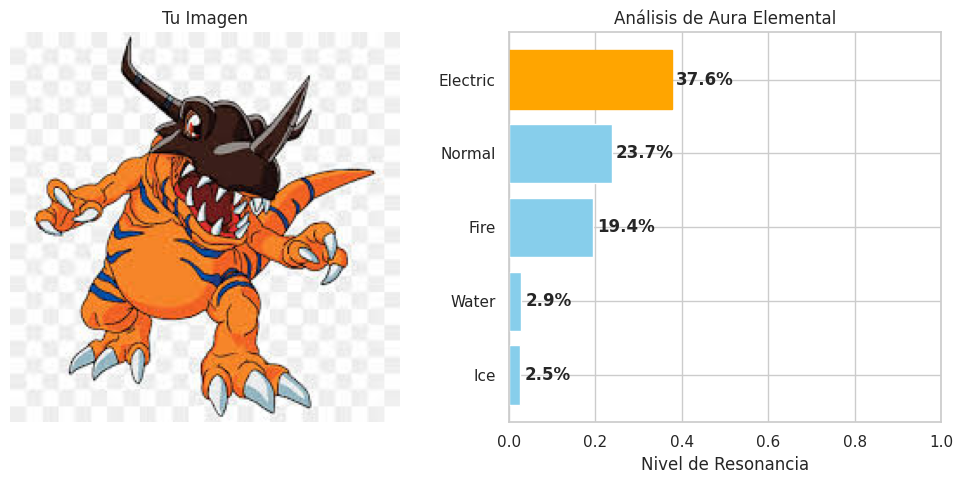

RESULTADO FINAL: ¡Esta imagen tiene alma de tipo ELECTRIC!
--------------------------------------------------


In [67]:
# Te pedirá subir un archivo.
escaner_de_aura(model_tipos, class_names)

# Entrenamiento de analisis de Estadisticas

In [69]:
"""
No generado por LLM

Diseño del modelo para analisis de estadisticas en los Pokemon proximos a diseñarse.

Se eliminan columnas que no se usaran: ['Image', 'Index', 'Name', 'Total']
Se llenaran los campos vacios del Type 2 con None
Se aplicara al texto un llenado de OneHotEncoding
Los valores numericos se escalaran en busca de normalizacion de los datos

"""

# Cargar datos
df = pd.read_excel('pokedex.xlsx')

# 1. Limpieza inicial
cols_to_drop = ['Image', 'Index', 'Name', 'Total']
df_clean = df.drop(columns=cols_to_drop)

# Manejo de Type 2 (reemplazar NaN por 'None')
df_clean['Type 2'] = df_clean['Type 2'].fillna('None')

# One-Hot Encoding para Type 1 y Type 2
encoder = OneHotEncoder(sparse_output=False)
types_encoded = encoder.fit_transform(df_clean[['Type 1', 'Type 2']])
type_features = encoder.get_feature_names_out(['Type 1', 'Type 2'])

# Escalamiento de estadísticas (HP, Attack, Defense, Sp. Atk., Sp. Def, Speed)
stats_cols = ['HP', 'Attack', 'Defense', 'SP. Atk.', 'SP. Def', 'Speed']
scaler = MinMaxScaler()
stats_scaled = scaler.fit_transform(df_clean[stats_cols])

# Combinar todo en un array de entrenamiento
X_all = np.hstack([types_encoded, stats_scaled])

# Entrenamiento del Modelo para analisis de los datos y predicción de estadisticas

In [70]:
"""
No generado por LLM

Construccion neuronal multicapa con aplicación de entrenamiento no supervisado al no poseer etiquetas.
Donde la salida puede ser cualquiera las 6 estadisticas que falten por predecir.

Por el EDA sabemos que existen multiples combinaciones de tipos y a la vez que por los boxplots sus estadisticas varian enormemente pero hay tipos que suelen ser mas fuertes o debiles que otros y mucho debe verse por sus tipos.
Para su validacion mantenemos margenes de confianza segun cuanto del resto de informacion se de, si no se da nada excepto los tipos maneja un margen 150% y si se da más estadisticas menos es ese margen, ya que tambien como se visualizó en el EDA con el mapa de correlacion existen variables altamente relacionadas y pueden hasta crearse nuevas matrices
por cada tipo existente, existe mucha variacion entre las estadisticas segun su tipo.

La validacion es exhaustiva es decir para cada fila se hace un analisis completo.
0: Todo a predecir, se toma los tipos, se predice, se calcula el error y si esta en el umbral de 150% se considera correcto.
1: 5 tipos a predecir, se usan los tipos el valor que se dan, se hace el analisis cuando se da solo el HP, otro cuando el ATK y etc, prediciendo los otros que no se alcanzan con un criterio de error de 125%.
...
...
...
5: 1 tipo a predecir, se usan los tipos, se ponen 5 de las 6 estadisticas y predice el faltante, si falta el HP, el ATK, la DEF y asi hasta cumplir los 6.
Cada fila se utiliza 6! es decir


"""


def build_model(input_dim, output_dim):
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),
        layers.Dense(output_dim, activation='linear') # Salida: las 6 estadísticas
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# La entrada incluye: Types_encoded (N columnas) + Stats (6 columnas)
# La salida será: Stats (6 columnas)
input_dim = X_all.shape[1]
output_dim = len(stats_cols)
model = build_model(input_dim, output_dim)

def validate_model_performance(model, val_data, scaler):
    """
    Evalúa el modelo en diferentes escenarios según la cantidad de
    información conocida.
    """
    # Umbrales de error relativo permitidos según cuánta info se conoce
    thresholds = {0: 1.50, 1: 1.25, 2: 1.00, 3: 0.75, 4: 0.60, 5: 0.50}

    # Diccionario para rastrear el éxito por cada cantidad de estadísticas conocidas
    results_by_r = {r: {"passed": 0, "total": 0} for r in range(6)}

    val_types = val_data[:, :-6]
    val_stats_scaled = val_data[:, -6:]
    val_stats_real = scaler.inverse_transform(val_stats_scaled)

    for i in range(len(val_data)):
        for r in range(6):
            # Generar todas las combinaciones posibles de 'r' estadísticas conocidas
            combos = list(itertools.combinations(range(6), r))

            for indices_conocidos in combos:
                results_by_r[r]["total"] += 1

                # Preparar la entrada con las estadísticas conocidas
                input_stats = np.zeros(6)
                for idx in indices_conocidos:
                    input_stats[idx] = val_stats_scaled[i, idx]

                full_input = np.hstack([val_types[i], input_stats]).reshape(1, -1)

                # Realizar predicción y revertir el escalado
                pred_scaled = model.predict(full_input, verbose=0)
                pred_real = scaler.inverse_transform(pred_scaled)[0]

                # Verificar si las estadísticas desconocidas cumplen el umbral
                indices_a_predecir = [idx for idx in range(6) if idx not in indices_conocidos]
                scenario_ok = True

                for idx in indices_a_predecir:
                    actual = val_stats_real[i, idx]
                    predicha = pred_real[idx]
                    error_relativo = abs(predicha - actual) / actual

                    if error_relativo > thresholds[r]:
                        scenario_ok = False
                        break

                if scenario_ok:
                    results_by_r[r]["passed"] += 1

    # Visualización de resultados en formato tabla
    print("\n" + "="*65)
    print(f"{'Stats Conocidas (r)':^20} | {'Éxitos':^12} | {'Total':^10} | {'% Éxito':^10}")
    print("-" * 65)

    global_passed, global_total = 0, 0
    for r in range(6):
        passed = results_by_r[r]["passed"]
        total = results_by_r[r]["total"]
        rate = (passed / total) * 100 if total > 0 else 0
        global_passed += passed
        global_total += total
        print(f"{r:^20} | {passed:^12} | {total:^10} | {rate:>8.2f}%")

    total_rate = global_passed / global_total
    print("-" * 65)
    print(f"{'TOTAL GLOBAL':^20} | {global_passed:^12} | {global_total:^10} | {total_rate*100:>8.2f}%")
    print("="*65 + "\n")

    return total_rate, global_passed, global_total

In [71]:
"""
No generado por LLM


Entrenamiento del modelo para obtención del resto de estadisticas.

Entrenamiento con num_epochs en busca del exito de 80%, para asegurarnos un modelo satisfactorio.
Cada epoca usara datos de entrenamiento y validacion distinto, esto con el fin de que no saque de casos a ciertos pokemons por temas de azar o determinación de una semilla.


Impresion de exitos para los 6 casos de no poseer estadisticas hasta solo la necesidad de predecir una de ellas, cada fila se procesa en sus 120 posibilidades.

El entrenamiento con 98% de la informacion sin etiquetar dura aproximadamente 1s
La validacion de solo 2% de la informacion al ser exhaustiva dura casi 2 mins

Se guarda el modelo que cumple la condicion de paro o cuando se alcanzan las 10 epocas. Condicion de paro 80% de exito. Es bajo pero se debe a una columna que es sumamente importante y es la fase, de haberse tenido posible se pueda aumentar a 95%.
"""

# Configuraciones
max_epochs = 10
required_success_rate = 0.8
best_rate = 0

for epoch in range(1, max_epochs + 1):
    # División de datos con nueva semilla por época
    X_train, X_val = train_test_split(X_all, test_size=0.02, random_state=epoch)
    y_train = X_train[:, -6:]

    print(f"\n--- Época {epoch} / {max_epochs} ---")
    model.fit(X_train, y_train, epochs=1, batch_size=32, verbose=1)

    # Evaluación detallada de escenarios
    print("Evaluando rendimiento por casos de uso...")
    rate, passed, total = validate_model_performance(model, X_val, scaler)

    # Guardar el mejor modelo
    if rate > best_rate:
        best_rate = rate
        model.save('best_pokemon_model.keras')

    # Verificar condición de parada
    if rate >= required_success_rate:
        print(f"¡Objetivo del {required_success_rate*100}% alcanzado!")
        break
    else:
        print(f"Faltó {(required_success_rate - rate)*100:.2f}% para el objetivo.")

print(f"\nEntrenamiento finalizado. Mejor tasa de éxito: {best_rate*100:.2f}%")


--- Época 1 / 10 ---
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0581 - mae: 0.1905
Evaluando rendimiento por casos de uso...

Stats Conocidas (r)  |    Éxitos    |   Total    |  % Éxito  
-----------------------------------------------------------------
         0           |      24      |     25     |    96.00%
         1           |     130      |    150     |    86.67%
         2           |     320      |    375     |    85.33%
         3           |     431      |    500     |    86.20%
         4           |     314      |    375     |    83.73%
         5           |     125      |    150     |    83.33%
-----------------------------------------------------------------
    TOTAL GLOBAL     |     1344     |    1575    |    85.33%

¡Objetivo del 80.0% alcanzado!

Entrenamiento finalizado. Mejor tasa de éxito: 85.33%


In [58]:
"""
No generado por LLM

Se guarda el encoder y scaler usado en los datos
"""


joblib.dump(encoder, 'pokemon_encoder.joblib')
joblib.dump(scaler, 'pokemon_scaler.joblib')

['pokemon_scaler.joblib']

# Carga de archivos

En caso de poseer los archivos, ahorrar los tiempos de entrenamiento:
1. Modelo: best_pokemon_model.keras
2. Encoder: pokemon_encoder.joblib
3. Scaler: pokemon_scaler.joblib

In [72]:
"""
No generado por LLM

Cargar el modelo y las herramientas de preprocesamiento. En caso de saltarse los entrenos.

"""

def inicializar_sistema():
    """Carga el modelo y las herramientas de preprocesamiento."""
    try:
        # Definimos el mapeo para que Keras encuentre 'mse'
        custom_objects = {
            'mse': tf.keras.losses.MeanSquaredError()
        }

        # Cargamos el modelo pasando los objetos personalizados
        model = tf.keras.models.load_model(
            'best_pokemon_model.keras',
            custom_objects=custom_objects
        )

        # Cargar el transformador de tipos y el escalador de números
        encoder = joblib.load('pokemon_encoder.joblib')
        scaler = joblib.load('pokemon_scaler.joblib')

        print("✅ Sistema cargado exitosamente.\n")
        return model, encoder, scaler
    except FileNotFoundError:
        print("❌ Error: No se encontraron los archivos del modelo.")
        return None, None, None
    except Exception as e:
        print(f"❌ Error inesperado al cargar: {e}")
        return None, None, None

model, encoder, scaler = inicializar_sistema()

✅ Sistema cargado exitosamente.



## Minijuego 4. Analizador de estadisticas

In [74]:
"""
No generado LLM

Explicacion del juego analizador de estadisticas

1. Solicita al usuario con un menu los tipos de pokemon puede ser un unico tipo o de dos
2. Solicita los datos que quiera dar y los que quiera predecir.
3. El modelo predice con los inputs dado las estadisticas que se deben predecir.
4. Ofrece interactividad al dar la opcion de ponerle nombre al Pokemon y poner el Total como un valor importante.

Objetivo: Practicidad, a ver se sabe todo, a veces no. La mejor forma de saber que algo funciona es entender el historico y de lo que ha generado exito en la empresa. Esta logica de juego puede funcionar a veces cuando poseemos algun bloqueo creativo y
cuesta decidir entre mantener e innovar. Por lo que esta ofrece una tendencia central y es cuestion del usuario decidir si sube, reduce o mantiene el valor. Segun como se tenia pensado.

"""

def pokemon_predictor_interface(name, t1, t2, user_stats):
    """
    name: str
    t1: str (Tipo 1)
    t2: str o None (Tipo 2)
    user_stats: dict con las 6 estadísticas (0 si es desconocido)
    """
    # 1. Preparar entrada para el modelo
    t2_val = t2 if t2 and t2 != 'Nulo' else 'None'

    # One-Hot Encoding de tipos
    types_input = encoder.transform([[t1, t2_val]])

    # Preparar vector de estadísticas (normalizado)
    # Llenamos con 0 lo que el usuario quiere predecir
    scaled_input_stats = []
    stats_to_predict = []

    for i, col in enumerate(stats_cols):
        val = user_stats[col]
        if val == 0:
            scaled_input_stats.append(0) # Valor temporal para la red
            stats_to_predict.append(col)
        else:
            # Escalar valor real a [0, 1]
            min_v = scaler.data_min_[i]
            max_v = scaler.data_range_[i]
            scaled_input_stats.append((val - min_v) / max_v)

    # 2. Ejecutar Red Neuronal
    full_input = np.hstack([types_input, [scaled_input_stats]])
    prediction_scaled = model.predict(full_input, verbose=0)
    prediction_real = scaler.inverse_transform(prediction_scaled)[0]

    # 3. Construir Resultado Final
    final_stats = {}
    for i, col in enumerate(stats_cols):
        if user_stats[col] == 0:
            # Es un valor predicho: redondear al entero más cercano
            final_stats[col] = int(round(prediction_real[i]))
        else:
            # Es el valor que el usuario ingresó
            final_stats[col] = user_stats[col]

    # Calcular Total
    total_score = sum(final_stats.values())

    # 4. Mostrar Resultados
    print("\n" + "="*30)
    print(f"RESULTADOS PARA: {name.upper()}")
    print(f"Tipos: {t1} / {t2_val}")
    print("-" * 30)
    for stat, val in final_stats.items():
        tag = "(Predicho)" if stat in stats_to_predict else "(Ingresado)"
        print(f"{stat:10}: {val} {tag}")
    print("-" * 30)
    print(f"TOTAL     : {total_score}")
    print("="*30)

    # Indicar margen de error según tus reglas
    num_dados = 6 - len(stats_to_predict)
    thresholds = {0: "150%", 1: "125%", 2: "100%", 3: "75%", 4: "60%", 5: "50%"}
    if len(stats_to_predict) > 0:
        print(f"Nota: Margen de error esperado: {thresholds.get(num_dados, 'N/A')}")

In [75]:
"""
No generado por LLM

Solicitud e Ingreso de datos.
Si es 0, indica que se debe predecir si es otro numero es algo que el usuario tiene claro.

"""

def run_interactive_menu():
    # Lista de tipos basada en el encoder
    tipos_disponibles = sorted(list(set(df['Type 1'])))

    print("--- CREADOR DE ESTADÍSTICAS POKÉMON ---")
    nombre = input("Nombre del Pokémon: ")

    def menu_tipos(label):
        print(f"\nSeleccione {label}:")
        for i, t in enumerate(tipos_disponibles):
            print(f"{i+1}. {t}")
        if label == "Type 2": print("0. Nulo")

        opcion = int(input("Opción num: "))
        if label == "Type 2" and opcion == 0: return "None"
        return tipos_disponibles[opcion-1]

    t1 = menu_tipos("Type 1")
    t2 = menu_tipos("Type 2")

    print("\nIngrese las estadísticas (Use '0' para predecir):")
    stats_usuario = {}
    for s in stats_cols:
        val = int(input(f"{s}: "))
        stats_usuario[s] = max(0, val) # Asegurar positivos

    # Llamar a la función de predicción
    pokemon_predictor_interface(nombre, t1, t2, stats_usuario)



In [76]:

"""
No generado por LLM

Solicitar cuantas veces se quiere hacer las predicciones.

Llenado de formularios
"""
def es_numero_entero_positivo(valor):
    try:
        numero = int(valor)
        return numero > 0
    except ValueError:
        return False

jugadas = ""
while not(es_numero_entero_positivo(jugadas)):
    jugadas = int(input("¿Cuántas veces quieres jugar? "))
    try:
      for _ in range(jugadas):
          run_interactive_menu()
    except ValueError:
      print("Por favor ingresa un número entero positivo.")


¿Cuántas veces quieres jugar? 1
--- CREADOR DE ESTADÍSTICAS POKÉMON ---
Nombre del Pokémon: Papita

Seleccione Type 1:
1. Bug
2. Dark
3. Dragon
4. Electric
5. Fairy
6. Fighting
7. Fire
8. Flying
9. Ghost
10. Grass
11. Ground
12. Ice
13. Normal
14. Poison
15. Psychic
16. Rock
17. Steel
18. Water
Opción num: 4

Seleccione Type 2:
1. Bug
2. Dark
3. Dragon
4. Electric
5. Fairy
6. Fighting
7. Fire
8. Flying
9. Ghost
10. Grass
11. Ground
12. Ice
13. Normal
14. Poison
15. Psychic
16. Rock
17. Steel
18. Water
0. Nulo
Opción num: 8

Ingrese las estadísticas (Use '0' para predecir):
HP: 60
Attack: 55
Defense: 80
SP. Atk.: 40
SP. Def: 0
Speed: 0

RESULTADOS PARA: PAPITA
Tipos: Electric / Flying
------------------------------
HP        : 60 (Ingresado)
Attack    : 55 (Ingresado)
Defense   : 80 (Ingresado)
SP. Atk.  : 40 (Ingresado)
SP. Def   : 50 (Predicho)
Speed     : 77 (Predicho)
------------------------------
TOTAL     : 362
Nota: Margen de error esperado: 60%
